# Bangla Multimodal Fake News: Preprocessing

This notebook prepares the BTMD dataset. It does **not** train any model, so a CPU runtime is enough.

Steps: mount Drive, unpack the code, check the code version, run preflight, build the unified table, make the group split, and run sanity checks.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Unpack the project code

The unpack cell always removes the old copy first, so stale code cannot run.

In [2]:
import shutil
import zipfile
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")
CODE_DIR = Path("/content/Bangla-Multimodal-FakeNews")

candidates = list(DRIVE_ROOT.glob("Bangla-Multimodal-FakeNews*.zip")) + list(
    (DRIVE_ROOT / "BFND-data").glob("Bangla-Multimodal-FakeNews*.zip")
)
assert candidates, "Code zip not found on Drive. Upload Bangla-Multimodal-FakeNews.zip first."
ZIP = max(candidates, key=lambda p: p.stat().st_mtime)
print("Using zip:", ZIP)

shutil.rmtree(CODE_DIR, ignore_errors=True)   # remove any old copy so stale code cannot run
with zipfile.ZipFile(ZIP) as z:
    z.extractall("/content")
print("Files in zip:", len(zipfile.ZipFile(ZIP).namelist()))

Using zip: /content/drive/MyDrive/Bangla-Multimodal-FakeNews.zip
Files in zip: 36


In [3]:
import os
from pathlib import Path

os.chdir(CODE_DIR)
config_text = Path("configs/config.py").read_text(encoding="utf-8")
assert "CLIP_IMAGE_MODEL" in config_text, (
    "Old code detected. Upload the latest zip to Drive, then run the unpack cell again."
)
print("Code version OK. Working directory:", os.getcwd())

Code version OK. Working directory: /content/Bangla-Multimodal-FakeNews


## 2. Install packages

Torch is already installed in Colab, so it is not installed here.

In [4]:
!pip install -q "pandas>=2.0" "scikit-learn>=1.3" "pyarrow>=14.0" "openpyxl>=3.1" "rank-bm25>=0.2.2" joblib pytest

## 3. Run the unit tests (no data needed)

In [5]:
!python -m pytest -q tests/

...............                                                          [100%]
15 passed in 4.16s


## 4. Preflight

Checks model IDs, schema, data files and the GPU. A GPU WARN is expected in this notebook. Any FAIL must be fixed before continuing.

In [6]:
!python scripts/00_preflight.py

[OK]   Hugging Face model: csebuetnlp/banglabert
[OK]   Hugging Face model: sentence-transformers/clip-ViT-B-32
[OK]   Hugging Face model: sentence-transformers/clip-ViT-B-32-multilingual-v1
[OK]   Hugging Face model: intfloat/multilingual-e5-base
[OK]   Hugging Face model: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
[WARN] btmd_schema.py: 'source_url_col' is not set; related features/guards will be skipped
[OK]   btmd_schema.py: required fields are filled in
[OK]   BTMD slim data: /content/drive/MyDrive/BFND-data/data/raw
[MISS] evidence.csv: /content/drive/MyDrive/BFND-data/data/evidence/evidence.csv
[MISS] cultural_annotations.csv: /content/drive/MyDrive/BFND-data/data/annotations/cultural_annotations.csv
[MISS] claim_evidence_pairs.csv: /content/drive/MyDrive/BFND-data/data/annotations/claim_evidence_pairs.csv
[WARN] No GPU. BanglaBERT and CLIP will be very slow on CPU. In Colab, set Runtime > Change runtime type > T4 GPU.

Experiments that can run:
  E1  BanglaBERT f

## 5. Build the unified table and the group split

In [7]:
!python scripts/01_prepare_data.py

label  Authentic  Misleading  Satire
split                               
test         337         219      32
train       1531        1074     131
val          340         216      30

Data stats: {'rows_raw': 6058, 'excluded_by_label': {'Clickbait': 576}, 'group_source': "column 'heading' (text hash when empty)", 'image_value_present_but_file_missing': 0, 'dropped_empty_text': 1566, 'dropped_duplicate_text_label': 1, 'dropped_duplicate_image': 5, 'rows_final': 3910, 'rows_with_image': 2397, 'label_counts': {'Authentic': 2208, 'Misleading': 1509, 'Satire': 193}}


## 6. Data statistics

In [8]:
import json
import pandas as pd
from configs.config import PROCESSED_DIR, RAW_DIR

stats = json.loads((PROCESSED_DIR / "data_stats.json").read_text(encoding="utf-8"))
for key, value in stats.items():
    print(f"{key}: {value}")

rows_raw: 6058
excluded_by_label: {'Clickbait': 576}
group_source: column 'heading' (text hash when empty)
image_value_present_but_file_missing: 0
dropped_empty_text: 1566
dropped_duplicate_text_label: 1
dropped_duplicate_image: 5
rows_final: 3910
rows_with_image: 2397
label_counts: {'Authentic': 2208, 'Misleading': 1509, 'Satire': 193}


## 7. Label mapping check

Each raw label should map to the expected project label.

In [9]:
unified = pd.read_csv(PROCESSED_DIR / "unified.csv")
print(pd.crosstab(unified["label_raw"], unified["label"], margins=True))

label           Authentic  Misleading  Satire   All
label_raw                                          
Misinformation          0        1509       0  1509
Real                 2208           0       0  2208
Satire                  0           0     193   193
All                  2208        1509     193  3910


## 8. Split check

Every split should contain all three classes.

In [10]:
split = pd.read_csv(PROCESSED_DIR / "unified_split.csv")
print(pd.crosstab(split["split"], split["label"], margins=True))

label  Authentic  Misleading  Satire   All
split                                     
test         337         219      32   588
train       1531        1074     131  2736
val          340         216      30   586
All         2208        1509     193  3910


## 9. Manual sample check

Read the 20 texts and check that each label looks right. Note any broken or suspicious rows.

In [11]:
pd.set_option("display.max_colwidth", 120)
print(unified.sample(20, random_state=7)[["sample_id", "label_raw", "label", "has_image", "text"]].to_string())

                                 sample_id       label_raw       label  has_image                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

## 10. Confound checks

Compare text length and source across classes. If they differ a lot, a model may learn the shortcut instead of the content.

In [12]:
unified["n_chars"] = unified["text"].str.len()
print("Text length (characters) by class:")
print(unified.groupby("label")["n_chars"].describe())

raw = pd.read_parquet(RAW_DIR / "data" / "metadata.parquet")
print("\nSource category by raw label:")
print(pd.crosstab(raw["multi_category"], raw["source_category"], margins=True))

Text length (characters) by class:
             count         mean          std   min   25%     50%     75%  \
label                                                                      
Authentic   2208.0  1428.651268  1563.552462   9.0  79.0  1136.0  2145.5   
Misleading  1509.0   438.131875   834.043531  11.0  64.0   100.0   342.0   
Satire       193.0   213.321244   532.602015   2.0  40.0    68.0   123.0   

                max  
label                
Authentic   17840.0  
Misleading   8616.0  
Satire       3934.0  

Source category by raw label:
source_category  Blog  Facebook  Instagram  Miscellaneous  News Channel  \
multi_category                                                            
Clickbait           0       100          0             69             3   
Misinformation      2      1383         10             27            34   
Real                0      1558          1              1           237   
Satire              0       586          3              0           

Next: open `02_model_training.ipynb` with a GPU runtime.

Total posts: 3910

Table 1: dataset card
             posts  with_image_pct  median_words  groups
label                                                   
Authentic   2208.0            62.9         167.0  2207.0
Misleading  1509.0            55.2          16.0  1506.0
Satire       193.0            90.7          10.0   193.0
All         3910.0            61.3          39.0  3906.0

Table 2: class counts per split
label  Authentic  Misleading  Satire  Total
split                                      
train       1531        1074     131   2736
val          340         216      30    586
test         337         219      32    588


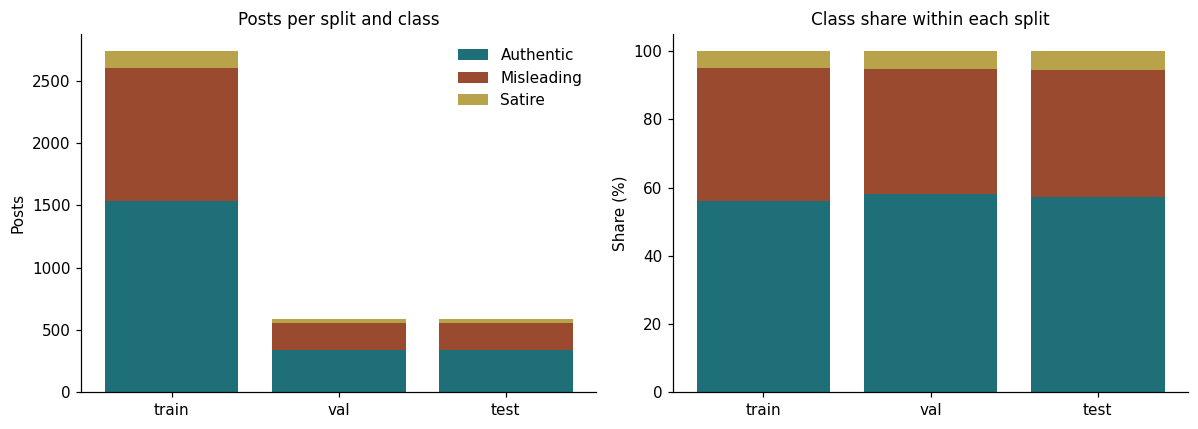

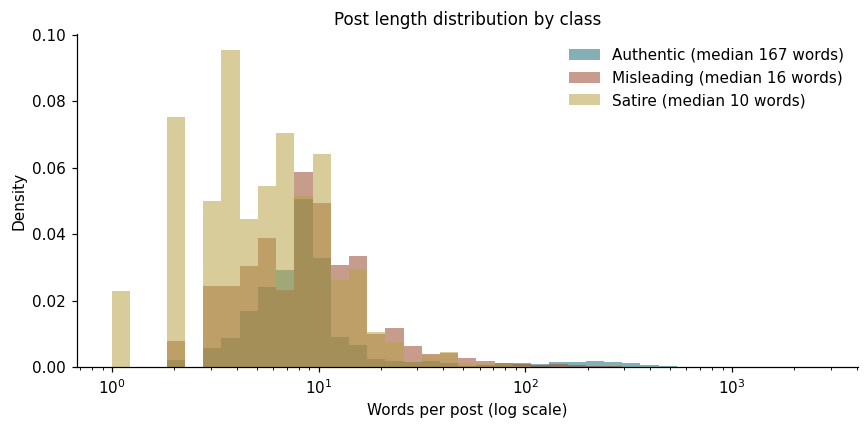

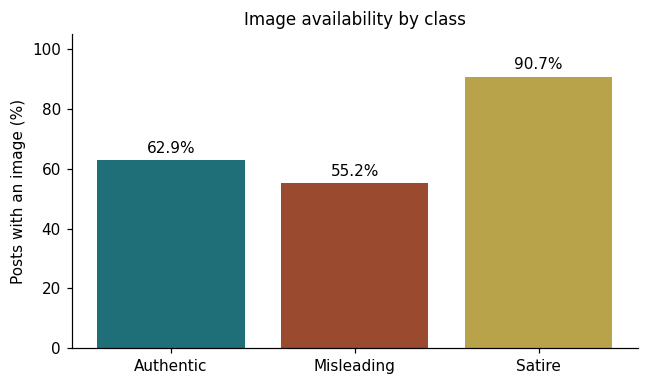


Groups: 3906 | posts per group, median: 1.0
Groups spanning more than one split: 0 (must be 0)


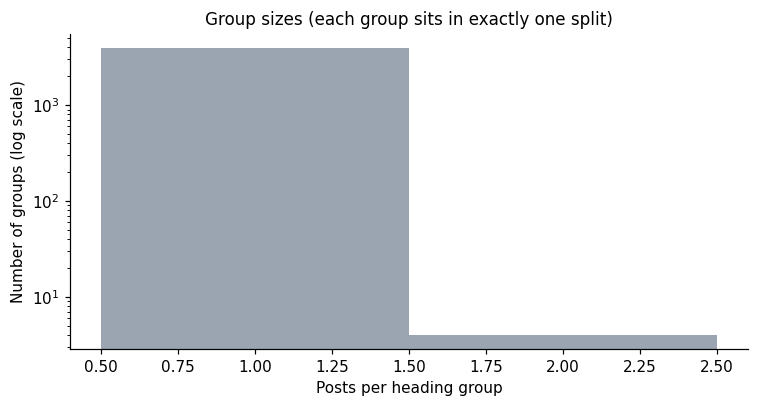


Preprocessing record (data_stats.json):
{
  "rows_raw": 6058,
  "excluded_by_label": {
    "Clickbait": 576
  },
  "group_source": "column 'heading' (text hash when empty)",
  "image_value_present_but_file_missing": 0,
  "dropped_empty_text": 1566,
  "dropped_duplicate_text_label": 1,
  "dropped_duplicate_image": 5,
  "rows_final": 3910,
  "rows_with_image": 2397,
  "label_counts": {
    "Authentic": 2208,
    "Misleading": 1509,
    "Satire": 193
  }
}

Table 3: examples
     label                                                                                                                   model_text  has_image
 Authentic প্লুটো কেন গ্রহ নয় তোমরা নিশ্চয়ই জানো, প্লুটো কোনো গ্রহ নয়। অথচ একসময় প্লুটোকে সৌরজগতের একটি গ্রহ হিসেবে ধরা হতো। স্ ...       True
 Authentic ১৬ অক্টোবর প্রকাশিত হবে এইচএসসি ও সমমান পরীক্ষার ফলাফল ১৬ অক্টোবর প্রকাশিত হবে এইচএসসি ও সমমান পরীক্ষার ফলাফল। আন্ত:শিক্ ...      False
Misleading ভালো করে নাচটা দেখুন। এটা সাংহাইয়ের ডিজনিল্যান্ডে হচ্ছে। এই দুই নর্তক

In [14]:
# Dataset overview for the paper: composition, splits, lengths, images, groups, samples.
# Reads saved files only. Trains nothing.
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from configs.config import FEATURE_DIR, LABELS_3, PROCESSED_DIR, RESULTS_DIR

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
PALETTE = {"Authentic": "#1f6f78", "Misleading": "#9a4b2f", "Satire": "#b8a24a"}
SPLITS = ["train", "val", "test"]


def save(fig, name):
    """Save each figure as PNG (for slides) and PDF (for the paper)."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


meta = pd.read_csv(FEATURE_DIR / "meta.csv", dtype={"sample_id": str})
meta["n_words"] = meta["model_text"].astype(str).str.split().str.len()
meta["has_image"] = meta["has_image"].astype(bool)
print("Total posts:", len(meta))

# ---- Table 1: dataset card (per class) ----
card = meta.groupby("label").agg(
    posts=("sample_id", "size"),
    with_image_pct=("has_image", "mean"),
    median_words=("n_words", "median"),
    groups=("group_id", "nunique"),
).reindex(LABELS_3)
card["with_image_pct"] = card["with_image_pct"] * 100
card.loc["All"] = [len(meta), meta["has_image"].mean() * 100,
                   meta["n_words"].median(), meta["group_id"].nunique()]
card.round(1).to_csv(FIG_DIR / "table_dataset_card.csv", encoding="utf-8-sig")
print("\nTable 1: dataset card")
print(card.round(1).to_string())

# ---- Table 2: class counts per split ----
split_table = pd.crosstab(meta["split"], meta["label"]).reindex(SPLITS)[LABELS_3]
split_table["Total"] = split_table.sum(axis=1)
split_table.to_csv(FIG_DIR / "table_split_counts.csv", encoding="utf-8-sig")
print("\nTable 2: class counts per split")
print(split_table.to_string())

# ---- Figure 1: class counts and class share per split ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = split_table[LABELS_3]
share = counts.div(counts.sum(axis=1), axis=0) * 100
for ax, values, ylabel, title in [
    (axes[0], counts, "Posts", "Posts per split and class"),
    (axes[1], share, "Share (%)", "Class share within each split"),
]:
    bottom = np.zeros(len(SPLITS))
    for label in LABELS_3:
        ax.bar(SPLITS, values[label], bottom=bottom, color=PALETTE[label], label=label)
        bottom += values[label].to_numpy()
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
axes[0].legend(frameon=False)
save(fig, "fig_dataset_splits")

# ---- Figure 2: post length distribution by class (words, log scale) ----
fig, ax = plt.subplots(figsize=(8, 4))
upper = max(float(meta["n_words"].max()), 10.0)
bins = np.logspace(0, np.log10(upper), 40)
for label in LABELS_3:
    vals = meta.loc[meta["label"] == label, "n_words"]
    ax.hist(vals, bins=bins, density=True, alpha=0.55, color=PALETTE[label],
            label=f"{label} (median {vals.median():.0f} words)")
ax.set_xscale("log")
ax.set_xlabel("Words per post (log scale)")
ax.set_ylabel("Density")
ax.set_title("Post length distribution by class", fontsize=11)
ax.legend(frameon=False)
save(fig, "fig_dataset_length")

# ---- Figure 3: image availability per class ----
img_pct = meta.groupby("label")["has_image"].mean().reindex(LABELS_3) * 100
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(LABELS_3, img_pct, color=[PALETTE[l] for l in LABELS_3])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 105)
ax.set_ylabel("Posts with an image (%)")
ax.set_title("Image availability by class", fontsize=11)
save(fig, "fig_dataset_images")

# ---- Figure 4: group structure and leakage check ----
group_sizes = meta.groupby("group_id").size()
spread = meta.groupby("group_id")["split"].nunique()
print("\nGroups:", len(group_sizes), "| posts per group, median:", group_sizes.median())
print("Groups spanning more than one split:", int((spread > 1).sum()), "(must be 0)")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(group_sizes, bins=np.arange(1, group_sizes.max() + 2) - 0.5, color=BASE_COLOR
        if (BASE_COLOR := "#9aa5b1") else None)
ax.set_yscale("log")
ax.set_xlabel("Posts per heading group")
ax.set_ylabel("Number of groups (log scale)")
ax.set_title("Group sizes (each group sits in exactly one split)", fontsize=11)
save(fig, "fig_dataset_groups")

# ---- Preprocessing record from data preparation ----
stats_path = PROCESSED_DIR / "data_stats.json"
if stats_path.exists():
    print("\nPreprocessing record (data_stats.json):")
    print(json.dumps(json.loads(stats_path.read_text(encoding="utf-8")), indent=2, ensure_ascii=False))
else:
    print("\n[MISS] data_stats.json not found in", PROCESSED_DIR)

# ---- Table 3: example posts per class ----
samples = pd.concat(
    [meta.loc[meta["label"] == c].sample(2, random_state=1) for c in LABELS_3]
)[["label", "model_text", "has_image"]].copy()
samples["model_text"] = samples["model_text"].astype(str).str.slice(0, 120) + " ..."
samples.to_csv(FIG_DIR / "table_examples.csv", index=False, encoding="utf-8-sig")
print("\nTable 3: examples")
print(samples.to_string(index=False))

print("\nSaved to:", FIG_DIR)